<a href="https://colab.research.google.com/github/carlaferraz/HorrorMoviesData/blob/main/HorrorMovieAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Perguntas


1.   Como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?
2.   Filmes de terror com maior orçamento recebem avaliações médias maiores do público?
3. Entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita/orçamento) maior que os de alto orçamento?
4. Quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?
5. Existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?
6. Filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

# Preparacao do Ambiente

In [17]:
!git clone https://github.com/carlaferraz/HorrorMoviesData.git

fatal: destination path 'HorrorMoviesData' already exists and is not an empty directory.


In [18]:
# Bibliotecas para manipulação e visualização dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis durante a aula
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


# Inicializaçao/ Ingestao

In [19]:
URL_DADOS = "https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/refs/heads/main/horror_movies.csv"

try:
    df_original = pd.read_csv(URL_DADOS)
except Exception as erro:
    raise RuntimeError(
        "Não foi possível carregar a base. Verifique a conexão com a internet."
    ) from erro

print("✓ Dados carregados com sucesso!")
print(f"Fonte: {URL_DADOS}")
print(f"Shape: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas")
print("\nPrimeiras linhas da base recebida:")
display(df_original.head())

✓ Dados carregados com sucesso!
Fonte: https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/refs/heads/main/horror_movies.csv
Shape: 32540 linhas × 21 colunas

Primeiras linhas da base recebida:


,Unnamed: 0,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,1,760161,Orphan: First Kill,Orphan: First Kill,en,After escaping from an Estonian psychiatric fa...,There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,"5,088.58",902,6.90,0.00,"9,572,765.00",99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller","760,193.00",Orphan Collection
1,2,760741,Beast,Beast,en,A recently widowed man and his two teenage dau...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,"2,172.34",584,7.10,0.00,"56,000,000.00",93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,3,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,"1,863.63",114,6.80,"17,000,000.00","45,000,000.00",115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,4,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,"1,071.40",2736,7.90,"18,800,000.00","161,000,000.00",103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,5,772450,Presencias,Presences,es,A man who loses his wife and goes to seclude h...,NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,"1,021.00",83,7.00,0.00,0.00,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


# Conhecimento

In [20]:
# Dicionário resumido das variáveis mais importantes para a demonstração
dicionario = pd.DataFrame({
    "coluna": [
        "Unnamed: 0", "id", "original_title", "title", "original_language",
        "overview", "tagline", "release_date", "poster_path", "popularity",
        "vote_count", "vote_average", "budget", "revenue", "runtime",
        "status", "adult", "backdrop_path", "genre_names", "collection",
        "collection_name"
    ],
    "significado": [
        "Número de linha do arquivo",
        "ID do filme no TMDB",
        "Título original",
        "Título internacional",
        "Idioma original",
        "Sinopse",
        "Slogan",
        "Data de lançamento",
        "Imagem do pôster",
        "Índice de popularidade",
        "Nº de votos",
        "Nota média (0 a 10)",
        "Orçamento",
        "Receita",
        "Duração (min)",
        "Situação de produção",
        "Conteúdo adulto(eita bixo🔞😳)",
        "Imagem de fundo",
        "Gêneros",
        "ID da coleção/franquia",
        "Nome da coleção/franquia"
    ],
})

display(dicionario.style.hide(axis="index"))

coluna,significado
Unnamed: 0,Número de linha do arquivo
id,ID do filme no TMDB
original_title,Título original
title,Título internacional
original_language,Idioma original
overview,Sinopse
tagline,Slogan
release_date,Data de lançamento
poster_path,Imagem do pôster
popularity,Índice de popularidade


# Inspecionar

A inspeção inicial responde perguntas básicas: qual é o tamanho da base, quais tipos foram inferidos, onde há valores ausentes e como os valores numéricos se distribuem?

Nesta etapa, ainda não alteramos nada.

In [21]:
print("VISÃO GERAL DA BASE ORIGINAL")
print("─" * 50)
print(f"Linhas:  {df_original.shape[0]}")
print(f"Colunas: {df_original.shape[1]}")
print(f"Células: {df_original.shape[0] * df_original.shape[1]:,}")

tipos = df_original.dtypes.astype(str).rename("tipo inferido").to_frame()
tipos.index.name = "coluna"
print("\nTipos inferidos pelo Pandas:")
display(tipos)

VISÃO GERAL DA BASE ORIGINAL
──────────────────────────────────────────────────
Linhas:  32540
Colunas: 21
Células: 683,340

Tipos inferidos pelo Pandas:


,tipo inferido
coluna,
Unnamed: 0,int64
id,int64
original_title,object
title,object
original_language,object
overview,object
tagline,object
release_date,object
poster_path,object


OBS: Blocos a seguir servem para identificar análises de possíveis problemas.
ex: colunas com muitos vazios, valores ausentes...
É importante para observar quais tipos de filtros devemos fazer pra nao quebrar tudo depois (ex: divisao por 0)

VALORES AUSENTES NA BASE ORIGINAL


,quantidade ausente,percentual ausente (%)
collection_name,30234,92.9%
collection,30234,92.9%
tagline,19836,61.0%
backdrop_path,18995,58.4%
poster_path,4474,13.7%
overview,1286,4.0%
original_language,0,0.0%
original_title,0,0.0%
id,0,0.0%
Unnamed: 0,0,0.0%


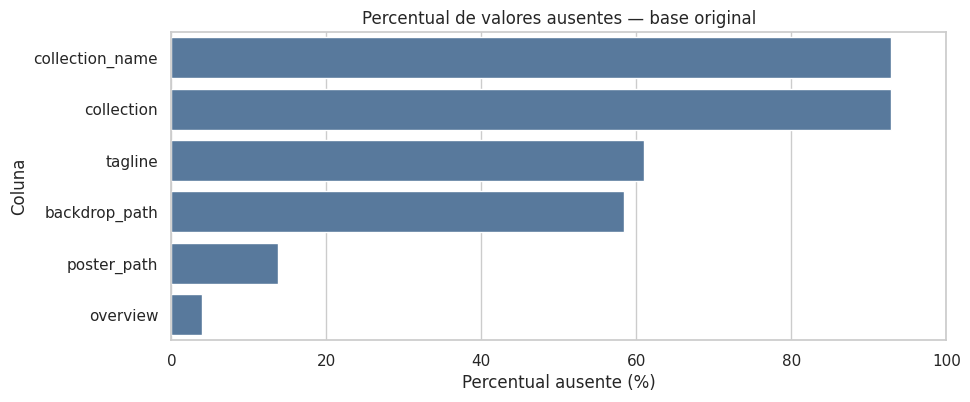

In [22]:
# Quantidade e percentual ajudam a avaliar a dimensão do problema
ausencias = pd.DataFrame({
    "quantidade ausente": df_original.isna().sum(),
    "percentual ausente (%)": df_original.isna().mean().mul(100)
}).sort_values("percentual ausente (%)", ascending=False)

print("VALORES AUSENTES NA BASE ORIGINAL")
display(ausencias.style.format({"percentual ausente (%)": "{:.1f}%"}))

# Mostramos apenas as colunas que realmente possuem ausências
ausencias_grafico = ausencias[ausencias["quantidade ausente"] > 0]
plt.figure(figsize=(10, 4))
sns.barplot(
    data=ausencias_grafico.reset_index(),
    x="percentual ausente (%)", y="index", color="#4C78A8"
)
plt.title("Percentual de valores ausentes — base original")
plt.xlabel("Percentual ausente (%)")
plt.ylabel("Coluna")
plt.xlim(0, 100)
plt.show()

In [7]:
print("ESTATÍSTICAS DAS COLUNAS NUMÉRICAS")
display(df_original.describe().T)

# Unnamed: 0 é sempre único, então fica de fora da comparação
linhas_iguais = int(df_original.drop(columns="Unnamed: 0").duplicated().sum())
print(f"\nLinhas com atributos observados iguais: {linhas_iguais}")
print("A duplicidade por id e por título + data é verificada em Q1, mais abaixo.")

ESTATÍSTICAS DAS COLUNAS NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"32,540.00","16,270.50","9,393.63",1.00,"8,135.75","16,270.50","24,405.25","32,540.00"
id,"32,540.00","445,910.83","305,744.67",17.00,"146,494.75","426,521.00","707,534.00","1,033,095.00"
popularity,"32,540.00",4.01,37.51,0.00,0.60,0.84,2.24,"5,088.58"
vote_count,"32,540.00",62.69,420.89,0.00,0.00,2.00,11.00,"16,900.00"
vote_average,"32,540.00",3.34,2.88,0.00,0.00,4.00,5.70,10.00
budget,"32,540.00","543,126.59","4,542,667.81",0.00,0.00,0.00,0.00,"200,000,000.00"
revenue,"32,540.00","1,349,746.73","14,430,479.15",0.00,0.00,0.00,0.00,"701,842,551.00"
runtime,"32,540.00",62.14,41.00,0.00,14.00,80.00,91.00,683.00
collection,"2,306.00","481,534.88","324,498.16",656.00,"155,421.00","471,259.00","759,067.25","1,033,032.00"



Linhas com atributos observados iguais: 0
A duplicidade por id e por título + data é verificada em Q1, mais abaixo.


# Avaliação da qualidade

Esta seção investiga os problemas da base antes da limpeza. Nada é alterado aqui: `df_original` continua igual ao arquivo lido.
Cada verificação tem um ID (Q1 a Q8), que é o mesmo usado no relatório e nas decisões de limpeza.

**Unidade de observação:** uma linha representa um filme cadastrado no TMDB com o gênero terror, no retrato coletado em outubro de 2022.

**Identificação dos registros:** a chave é `id` (identificador do filme no TMDB). `Unnamed: 0` é só o número da linha herdado da exportação e não identifica o filme.

In [8]:
# A base foi publicada no TidyTuesday em 01/11/2022; datas depois disso ainda não tinham acontecido na coleta
DATA_COLETA = pd.Timestamp("2022-11-01")
TOTAL = len(df_original)

datas = pd.to_datetime(df_original["release_date"], format="%Y-%m-%d", errors="coerce")
generos = df_original["genre_names"].str.split(", ")

# Guarda o resultado de cada verificação para o resumo no final da seção
diagnostico = {}

def registrar(qid, verificacao, resultado):
    diagnostico[(qid, verificacao)] = resultado

def pct(n):
    return f"{n:,} ({n / TOTAL:.1%})"

print("✓ Variáveis auxiliares prontas.")

✓ Variáveis auxiliares prontas.


## Dicionário com tipos e domínios

Complementa o dicionário acima com o tipo que o Pandas inferiu, o tipo esperado para cada atributo e o domínio observado.

In [9]:
tipo_esperado = {
    "Unnamed: 0": "inteiro (índice)", "id": "inteiro", "original_title": "texto", "title": "texto",
    "original_language": "categoria (ISO 639-1)", "overview": "texto", "tagline": "texto",
    "release_date": "data", "poster_path": "texto (caminho)", "popularity": "decimal ≥ 0",
    "vote_count": "inteiro ≥ 0", "vote_average": "decimal de 0 a 10", "budget": "inteiro ≥ 0 (US$)",
    "revenue": "inteiro ≥ 0 (US$)", "runtime": "inteiro > 0 (minutos)", "status": "categoria",
    "adult": "booleano", "backdrop_path": "texto (caminho)", "genre_names": "lista de categorias",
    "collection": "identificador", "collection_name": "texto",
}

def dominio(coluna):
    serie = df_original[coluna]
    if coluna == "release_date":
        return f"{datas.min():%Y-%m-%d} a {datas.max():%Y-%m-%d}"
    if pd.api.types.is_bool_dtype(serie):
        return ", ".join(map(str, serie.unique()))
    if pd.api.types.is_numeric_dtype(serie):
        return f"{serie.min():,.2f} a {serie.max():,.2f}"
    if serie.nunique() <= 10:
        return ", ".join(serie.dropna().unique())
    return "ex.: " + str(serie.dropna().iloc[0])[:40]

dicionario_tipos = pd.DataFrame({
    "coluna": df_original.columns,
    "tipo inferido": df_original.dtypes.astype(str).values,
    "tipo esperado": [tipo_esperado[c] for c in df_original.columns],
    "ausentes": df_original.isna().sum().values,
    "valores distintos": df_original.nunique().values,
    "domínio observado": [dominio(c) for c in df_original.columns],
})
display(dicionario_tipos.style.hide(axis="index"))

coluna,tipo inferido,tipo esperado,ausentes,valores distintos,domínio observado
Unnamed: 0,int64,inteiro (índice),0,32540,"1.00 a 32,540.00"
id,int64,inteiro,0,32540,"17.00 a 1,033,095.00"
original_title,str,texto,0,30296,ex.: Orphan: First Kill
title,str,texto,0,29563,ex.: Orphan: First Kill
original_language,str,categoria (ISO 639-1),0,97,ex.: en
overview,str,texto,1286,31020,ex.: After escaping from an Estonian psychiat
tagline,str,texto,19836,12512,ex.: There's always been something wrong with
release_date,str,data,0,10999,1950-01-01 a 2022-12-31
poster_path,str,texto (caminho),4474,28048,ex.: /pHkKbIRoCe7zIFvqan9LFSaQAde.jpg
popularity,float64,decimal ≥ 0,0,7250,"0.00 a 5,088.58"


## Q1 — Unicidade dos registros

Regras: `id` não pode se repetir; não pode haver linhas idênticas; e dois registros com o mesmo título e a mesma data de lançamento são candidatos a cadastro duplicado.

In [10]:
print("Q1 — UNICIDADE DOS REGISTROS")
print("─" * 50)

ids_repetidos = int(df_original["id"].duplicated().sum())
linhas_repetidas = int(df_original.drop(columns="Unnamed: 0").duplicated().sum())
mesmo_titulo_data = df_original[df_original.duplicated(["title", "release_date"], keep=False)]

print(f"ids repetidos: {ids_repetidos}")
print(f"linhas idênticas (sem Unnamed: 0): {linhas_repetidas}")
print(f"registros com mesmo título e data: {len(mesmo_titulo_data)} ({len(mesmo_titulo_data) // 2} pares)")
display(
    mesmo_titulo_data.sort_values(["title", "release_date"])
    [["id", "title", "release_date", "runtime", "vote_count", "overview"]]
)

registrar("Q1", "id repetido", ids_repetidos)
registrar("Q1", "linha idêntica (sem Unnamed: 0)", linhas_repetidas)
registrar("Q1", "mesmo título + data de lançamento", f"{len(mesmo_titulo_data)} registros em {len(mesmo_titulo_data) // 2} pares")

Q1 — UNICIDADE DOS REGISTROS
──────────────────────────────────────────────────


ids repetidos: 0
linhas idênticas (sem Unnamed: 0): 0
registros com mesmo título e data: 8 (4 pares)


,id,title,release_date,runtime,vote_count,overview
15991,323508,Angels Die Slowly,2010-02-01,86,0,"On a hot summer night in New Orleans, Angel an..."
31954,988409,Angels Die Slowly,2010-02-01,0,0,"On a hot summer night in New Orleans, Angel an..."
442,1017246,Cracked,2022-02-24,93,11,Ruja inherited the painting from her deceased ...
4531,821669,Cracked,2022-02-24,93,9,Ruja inherited a collection of paintings from ...
1415,581531,Metamorphosis,2019-08-21,113,154,An evil spirit that changes faces infiltrates ...
26522,669600,Metamorphosis,2019-08-21,0,1,NaN
5601,10042,Within,2005-01-01,95,27,8 explorers trapped in a Russian cave system a...
6861,360651,Within,2005-01-01,93,5,"Brad, Christina, T.K. and Kelly are on a post-..."


**Leitura:** a chave `id` é única e não há linhas copiadas. Dos 4 pares com mesmo título e data, *Cracked* e *Within* têm sinopses diferentes e são filmes distintos.
*Angels Die Slowly* tem a mesma sinopse nos dois registros, e um deles está com duração 0: é provavelmente o mesmo filme cadastrado duas vezes.
Em *Metamorphosis*, um registro não tem sinopse, tem 1 voto e duração 0, então não dá para confirmar se é o mesmo filme.
A duplicidade real é pequena (1 ou 2 registros) e não afeta as análises.

## Q2 — Valores ausentes explícitos (NaN)

Regra: para cada coluna com ausências, verificar se ela é usada nas perguntas e o que a ausência significa.

In [11]:
print("Q2 — VALORES AUSENTES EXPLÍCITOS")
print("─" * 50)

uso = {
    "overview": "não", "tagline": "não", "poster_path": "não", "backdrop_path": "não",
    "collection": "P6", "collection_name": "P6",
}
significado_ausencia = {
    "overview": "filme sem sinopse cadastrada",
    "tagline": "filme sem slogan cadastrado",
    "poster_path": "filme sem pôster",
    "backdrop_path": "filme sem imagem de fundo",
    "collection": "filme não pertence a uma franquia",
    "collection_name": "filme não pertence a uma franquia",
}
nulos = df_original.isna().sum()
nulos = nulos[nulos > 0]
ausentes_q2 = pd.DataFrame({
    "coluna": nulos.index,
    "ausentes": [pct(int(n)) for n in nulos.values],
    "usada nas perguntas": [uso[c] for c in nulos.index],
    "o que a ausência significa": [significado_ausencia[c] for c in nulos.index],
})
display(ausentes_q2.style.hide(axis="index"))

colunas_completas = [c for c in df_original.columns if c not in nulos.index]
print(f"Colunas sem nenhum NaN: {len(colunas_completas)} de {df_original.shape[1]}")

for coluna, n in nulos.items():
    registrar("Q2", f"NaN em {coluna}", pct(int(n)))

Q2 — VALORES AUSENTES EXPLÍCITOS
──────────────────────────────────────────────────


coluna,ausentes,usada nas perguntas,o que a ausência significa
overview,"1,286 (4.0%)",não,filme sem sinopse cadastrada
tagline,"19,836 (61.0%)",não,filme sem slogan cadastrado
poster_path,"4,474 (13.7%)",não,filme sem pôster
backdrop_path,"18,995 (58.4%)",não,filme sem imagem de fundo
collection,"30,234 (92.9%)",P6,filme não pertence a uma franquia
collection_name,"30,234 (92.9%)",P6,filme não pertence a uma franquia


Colunas sem nenhum NaN: 15 de 21


**Leitura:** as ausências explícitas estão só em colunas de texto e imagem, que não entram nas perguntas, e em `collection`/`collection_name`.
Nestas duas, NaN não é dado faltando: significa que o filme é avulso (não pertence a uma franquia), e é exatamente o grupo de comparação de P6.
Nenhuma dessas ausências precisa ser preenchida. O problema maior de ausência está escondido nos zeros (Q3).

## Q3 — Ausências disfarçadas de zero

O TMDB grava 0 quando o campo não foi informado. Um filme não tem orçamento de US$ 0 nem duração de 0 minutos, e nota 0 sem nenhum voto quer dizer "sem avaliação".
Regra: contar os zeros em cada atributo numérico usado nas perguntas.

In [12]:
print("Q3 — AUSÊNCIAS DISFARÇADAS DE ZERO")
print("─" * 50)

sem_votos = df_original["vote_count"] == 0
regras_zero = {
    "budget = 0": df_original["budget"] == 0,
    "revenue = 0": df_original["revenue"] == 0,
    "budget = 0 ou revenue = 0": (df_original["budget"] == 0) | (df_original["revenue"] == 0),
    "runtime = 0": df_original["runtime"] == 0,
    "vote_count = 0 (nenhum voto)": sem_votos,
    "vote_average = 0 e vote_count = 0": sem_votos & (df_original["vote_average"] == 0),
    "popularity = 0": df_original["popularity"] == 0,
}
zeros_q3 = pd.DataFrame({
    "regra": list(regras_zero),
    "registros": [pct(int(m.sum())) for m in regras_zero.values()],
})
display(zeros_q3.style.hide(axis="index"))

com_financeiro = int(((df_original["budget"] > 0) & (df_original["revenue"] > 0)).sum())
print(f"Filmes com orçamento E receita informados (base de P3): {pct(com_financeiro)}")

for regra, mascara in regras_zero.items():
    registrar("Q3", regra, pct(int(mascara.sum())))
registrar("Q3", "budget > 0 e revenue > 0 (base de P3)", pct(com_financeiro))

Q3 — AUSÊNCIAS DISFARÇADAS DE ZERO
──────────────────────────────────────────────────


regra,registros
budget = 0,"27,339 (84.0%)"
revenue = 0,"30,964 (95.2%)"
budget = 0 ou revenue = 0,"31,442 (96.6%)"
runtime = 0,"2,668 (8.2%)"
vote_count = 0 (nenhum voto),"11,602 (35.7%)"
vote_average = 0 e vote_count = 0,"11,590 (35.6%)"
popularity = 0,2 (0.0%)


Filmes com orçamento E receita informados (base de P3): 1,098 (3.4%)


**Leitura:** este é o problema mais grave da base. 84% dos filmes não têm orçamento e 95% não têm receita, e só 1.098 filmes (3,4%) têm os dois, que é a base possível para P3.
Cerca de 8% dos filmes têm duração 0, e um terço não recebeu nenhum voto, o que faz o `vote_average` 0 aparecer como se fosse uma nota real.
Se esses zeros forem usados como valores, médias de orçamento, nota e duração ficam puxadas para baixo e a divisão receita/orçamento quebra (divisão por zero).

## Q4 — Tipos de dados

Regra: comparar o tipo inferido com o esperado e testar se os valores podem ser convertidos sem perda.

In [13]:
print("Q4 — TIPOS DE DADOS")
print("─" * 50)

def inteiros(serie):
    serie = serie.dropna()
    return bool((serie % 1 == 0).all())

tipos_q4 = pd.DataFrame([
    {"coluna": "release_date", "tipo inferido": str(df_original["release_date"].dtype), "esperado": "data",
     "teste": "converte no formato AAAA-MM-DD", "falhas": int(datas.isna().sum())},
    {"coluna": "collection", "tipo inferido": str(df_original["collection"].dtype), "esperado": "identificador",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["collection"].dropna() % 1 == 0)).sum())},
    {"coluna": "budget", "tipo inferido": str(df_original["budget"].dtype), "esperado": "inteiro",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["budget"] % 1 == 0)).sum())},
    {"coluna": "revenue", "tipo inferido": str(df_original["revenue"].dtype), "esperado": "inteiro",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["revenue"] % 1 == 0)).sum())},
    {"coluna": "adult", "tipo inferido": str(df_original["adult"].dtype), "esperado": "booleano",
     "teste": "valores distintos", "falhas": int(df_original["adult"].nunique())},
    {"coluna": "Unnamed: 0", "tipo inferido": str(df_original["Unnamed: 0"].dtype), "esperado": "índice",
     "teste": "é a sequência 1..n", "falhas": int((df_original["Unnamed: 0"] != np.arange(1, TOTAL + 1)).sum())},
])
display(tipos_q4.style.hide(axis="index"))

registrar("Q4", "release_date como texto", f"tipo {df_original['release_date'].dtype}; {int(datas.isna().sum())} falhas ao converter para data")
registrar("Q4", "collection como decimal", f"tipo {df_original['collection'].dtype} por causa dos NaN; todos os valores são inteiros")
registrar("Q4", "budget e revenue como decimal", "todos os valores são inteiros")
registrar("Q4", "adult", f"um único valor ({df_original['adult'].unique()[0]}) em todas as linhas")
registrar("Q4", "Unnamed: 0", "é só a sequência 1..n")

Q4 — TIPOS DE DADOS
──────────────────────────────────────────────────


coluna,tipo inferido,esperado,teste,falhas
release_date,str,data,converte no formato AAAA-MM-DD,0
collection,float64,identificador,todos os valores são inteiros,0
budget,float64,inteiro,todos os valores são inteiros,0
revenue,float64,inteiro,todos os valores são inteiros,0
adult,bool,booleano,valores distintos,1
Unnamed: 0,int64,índice,é a sequência 1..n,0


**Leitura:** `release_date` veio como texto, mas todas as 32.540 datas estão no formato AAAA-MM-DD e convertem sem falha; precisa virar data para extrair ano, década e mês (P1 e P5).
`collection` virou decimal só porque tem NaN (o Pandas não guarda NaN em coluna inteira); os valores são inteiros e devem ser tratados como identificador.
`budget` e `revenue` também são inteiros guardados como decimal, sem efeito nas contas.
`adult` tem o mesmo valor (False) em todas as linhas, então não carrega informação. `Unnamed: 0` é só o número da linha.

## Q5 — Domínios, período e situação de lançamento

Regras: nenhum valor numérico negativo; `vote_average` entre 0 e 10; datas dentro do recorte de 1950 a 2022; filme lançado não pode ter data posterior à coleta.

In [14]:
print("Q5 — DOMÍNIOS, PERÍODO E SITUAÇÃO")
print("─" * 50)

numericas = ["popularity", "vote_count", "vote_average", "budget", "revenue", "runtime"]
negativos = int((df_original[numericas] < 0).sum().sum())
nota_fora = int(((df_original["vote_average"] < 0) | (df_original["vote_average"] > 10)).sum())
fora_recorte = int(((datas < "1950-01-01") | (datas > "2022-12-31")).sum())
depois_coleta = datas > DATA_COLETA
nao_lancados = df_original["status"] != "Released"

print(f"valores negativos nas colunas numéricas: {negativos}")
print(f"vote_average fora de 0–10: {nota_fora}")
print(f"datas fora de 1950–2022: {fora_recorte}")
print(f"datas depois da coleta (> {DATA_COLETA:%d/%m/%Y}): {int(depois_coleta.sum())}")
print(f"filmes com status diferente de Released: {int(nao_lancados.sum())}")
print(f"  desses, com algum voto: {int((nao_lancados & (df_original['vote_count'] > 0)).sum())}")

print("\nStatus × data depois da coleta:")
display(pd.crosstab(df_original["status"], depois_coleta.rename("data depois da coleta")))

registrar("Q5", "valores negativos", negativos)
registrar("Q5", "vote_average fora de 0–10", nota_fora)
registrar("Q5", "data fora de 1950–2022", fora_recorte)
registrar("Q5", "data depois da coleta", int(depois_coleta.sum()))
registrar("Q5", "status diferente de Released", pct(int(nao_lancados.sum())))
registrar("Q5", "Released com data depois da coleta", int((depois_coleta & ~nao_lancados).sum()))

Q5 — DOMÍNIOS, PERÍODO E SITUAÇÃO
──────────────────────────────────────────────────
valores negativos nas colunas numéricas: 0
vote_average fora de 0–10: 0
datas fora de 1950–2022: 0
datas depois da coleta (> 01/11/2022): 59
filmes com status diferente de Released: 135
  desses, com algum voto: 0

Status × data depois da coleta:


data depois da coleta,False,True
status,,
In Production,42,27
Planned,5,0
Post Production,39,22
Released,32395,10


**Leitura:** não há negativos, notas fora da escala nem datas fora do recorte.
O ponto de atenção são os 135 filmes que ainda não tinham sido lançados (em produção, pós-produção ou planejados): nenhum tem voto, e muitos têm data futura.
Eles não têm como ter nota, receita ou popularidade de lançamento, então distorcem P2 a P6. Há ainda 10 filmes marcados como Released com data depois da coleta, uma inconsistência de cadastro.

## Q6 — Coerência entre campos

Regras: nota e quantidade de votos precisam concordar; `collection` e `collection_name` precisam andar juntos; receita sem orçamento é registrada para P3.

In [15]:
print("Q6 — COERÊNCIA ENTRE CAMPOS")
print("─" * 50)

nota_sem_voto = (df_original["vote_count"] == 0) & (df_original["vote_average"] > 0)
voto_sem_nota = (df_original["vote_count"] > 0) & (df_original["vote_average"] == 0)
colecao_sem_nome = df_original["collection"].isna() != df_original["collection_name"].isna()
nomes_por_colecao = int((df_original.groupby("collection")["collection_name"].nunique() > 1).sum())
receita_sem_orcamento = (df_original["revenue"] > 0) & (df_original["budget"] == 0)

coerencia_q6 = pd.DataFrame({
    "regra": [
        "nota > 0 sem nenhum voto",
        "votos > 0 com nota 0",
        "collection preenchido sem collection_name (ou o contrário)",
        "um mesmo collection com mais de um nome",
        "receita > 0 com orçamento 0",
    ],
    "registros": [
        int(nota_sem_voto.sum()), int(voto_sem_nota.sum()), int(colecao_sem_nome.sum()),
        nomes_por_colecao, int(receita_sem_orcamento.sum()),
    ],
})
display(coerencia_q6.style.hide(axis="index"))

print("Exemplos de nota sem voto e de voto sem nota:")
display(df_original.loc[nota_sem_voto | voto_sem_nota, ["id", "title", "vote_count", "vote_average"]].head(8))

for regra, n in zip(coerencia_q6["regra"], coerencia_q6["registros"]):
    registrar("Q6", regra, int(n))

Q6 — COERÊNCIA ENTRE CAMPOS
──────────────────────────────────────────────────


regra,registros
nota > 0 sem nenhum voto,12
votos > 0 com nota 0,39
collection preenchido sem collection_name (ou o contrário),0
um mesmo collection com mais de um nome,0
receita > 0 com orçamento 0,478


Exemplos de nota sem voto e de voto sem nota:


,id,title,vote_count,vote_average
2590,952813,The Legend of Johnny Jones,1,0.00
3243,1028243,The Last Of Us : All Gone,0,8.00
4884,269736,Fatal Love,1,0.00
8022,308441,Amuse Me,1,0.00
9120,931529,Unboxed,1,0.00
9230,671248,Sanzaru,1,0.00
10096,531807,Mr. Zombie 2,1,0.00
10897,435417,Something Sinister,1,0.00


**Leitura:** 12 filmes têm nota sem nenhum voto e 39 têm votos com nota 0, o que não é possível na escala do TMDB (as notas vão de 0,5 a 10). São poucos casos, mas a nota deles não é confiável.
`collection` e `collection_name` são totalmente coerentes: sempre aparecem juntos e cada franquia tem um nome só, então P6 pode usar qualquer um dos dois.
Os 478 filmes com receita e sem orçamento ficam fora de P3, porque não dá para calcular o retorno.

## Q7 — Categorias e formatos

Regras: todo filme da base deve ter "Horror" em `genre_names`, sem gênero repetido; `original_language` deve seguir os códigos ISO 639-1; textos sem espaços sobrando nas pontas.

In [16]:
print("Q7 — CATEGORIAS E FORMATOS")
print("─" * 50)

sem_horror = ~generos.apply(lambda lista: "Horror" in lista)
genero_repetido = generos.apply(lambda lista: len(lista) != len(set(lista)))
vocabulario = generos.explode().value_counts()

print(f"gêneros distintos: {len(vocabulario)}")
print(f"filmes sem 'Horror' em genre_names: {int(sem_horror.sum())}")
display(df_original.loc[sem_horror, ["id", "title", "genre_names"]])
print(f"filmes com gênero repetido: {int(genero_repetido.sum())}")
display(df_original.loc[genero_repetido, ["id", "title", "genre_names"]])

# cn: código do TMDB para cantonês (não é ISO); xx: sem idioma; sh: servo-croata (código retirado da ISO)
codigos_especiais = {"cn": "cantonês (código próprio do TMDB)", "xx": "sem idioma / sem diálogo", "sh": "servo-croata (código obsoleto)"}
idiomas = df_original["original_language"].value_counts()
idiomas_q7 = pd.DataFrame({
    "código": list(codigos_especiais),
    "significado": list(codigos_especiais.values()),
    "filmes": [int(idiomas.get(c, 0)) for c in codigos_especiais],
})
print(f"\nidiomas distintos: {df_original['original_language'].nunique()} — códigos fora do padrão ISO 639-1:")
display(idiomas_q7.style.hide(axis="index"))

textos = ["title", "original_title", "genre_names", "collection_name", "original_language", "status"]
espacos = {c: int((df_original[c].dropna() != df_original[c].dropna().str.strip()).sum()) for c in textos}
print("Textos com espaço sobrando nas pontas:", espacos)

registrar("Q7", "genre_names sem 'Horror'", int(sem_horror.sum()))
registrar("Q7", "gênero repetido no mesmo filme", int(genero_repetido.sum()))
registrar("Q7", "original_language fora da ISO (cn, xx, sh)", int(idiomas_q7["filmes"].sum()))
registrar("Q7", "texto com espaço sobrando", sum(espacos.values()))

Q7 — CATEGORIAS E FORMATOS
──────────────────────────────────────────────────
gêneros distintos: 19
filmes sem 'Horror' em genre_names: 4


,id,title,genre_names
12802,41105,Kamen Rider: The Next,"Action, Adventure, Science Fiction"
13209,250883,Nak,"Adventure, Animation, Comedy, Fantasy"
13266,533130,I Dance on Your Grave,Thriller
32196,1005102,Smog,"Drama, Mystery"


filmes com gênero repetido: 8


,id,title,genre_names
12296,181282,The Haunting of M.,"Horror, Horror"
12616,534282,Head,"Comedy, Horror, Horror"
15372,264738,The Haunting at Thompson High,"Horror, Horror"
15381,90355,The Gardener,"Horror, Horror"
22886,446378,It Began Without Warning,"Horror, Horror"
23135,457572,Membabi Buta,"Horror, Horror, Thriller"
24484,537963,Judas,"Horror, Music, Music"
25852,632601,East Hell,"Horror, Horror"



idiomas distintos: 97 — códigos fora do padrão ISO 639-1:


código,significado,filmes
cn,cantonês (código próprio do TMDB),423
xx,sem idioma / sem diálogo,75
sh,servo-croata (código obsoleto),25


Textos com espaço sobrando nas pontas: {'title': 0, 'original_title': 1, 'genre_names': 0, 'collection_name': 0, 'original_language': 0, 'status': 0}


**Leitura:** 4 filmes estão na base de terror mas não têm "Horror" na lista de gêneros, e 8 têm um gênero repetido (ex.: "Horror, Horror"), o que dobra a contagem em P4.
Fora isso, o vocabulário de gêneros é limpo: 19 nomes, sempre separados por vírgula e espaço.
Em idiomas, `cn` (423 filmes) e `zh` (496) são ambos chinês e precisam ser considerados juntos ou explicitamente separados em P1; `xx` e `sh` são poucos casos.
Só 1 título tem espaço sobrando (um espaço japonês no fim de `original_title`), sem impacto.

## Q8 — Valores extremos e suspeitos

Regras: orçamento ou receita entre US$ 1 e US$ 999 é suspeito; duração acima de 300 minutos ou abaixo de 40 indica que o registro pode não ser um longa-metragem; nota 10 com 1 ou 2 votos não é confiável.
Valor extremo, sozinho, não é erro: a ideia aqui é separar o que é suspeito do que é real.

In [17]:
print("Q8 — VALORES EXTREMOS E SUSPEITOS")
print("─" * 50)

orcamento_baixo = df_original["budget"].between(1, 999)
receita_baixa = df_original["revenue"].between(1, 999)
muito_longo = df_original["runtime"] > 300
curta = df_original["runtime"].between(1, 39)
nota_10 = df_original["vote_average"] == 10
poucos_votos = df_original["vote_count"] < 10

extremos_q8 = pd.DataFrame({
    "regra": [
        "budget entre US$ 1 e 999", "revenue entre US$ 1 e 999", "runtime > 300 min",
        "runtime entre 1 e 39 min (curta)", "vote_average = 10", "vote_average = 10 com até 2 votos",
        "menos de 10 votos",
    ],
    "registros": [pct(int(m.sum())) for m in [
        orcamento_baixo, receita_baixa, muito_longo, curta, nota_10,
        nota_10 & (df_original["vote_count"] <= 2), poucos_votos,
    ]],
})
display(extremos_q8.style.hide(axis="index"))

print("Orçamentos suspeitos (amostra):")
display(df_original.loc[orcamento_baixo, ["title", "budget", "revenue"]].head(6))
print("Durações acima de 300 minutos:")
display(df_original.loc[muito_longo, ["title", "release_date", "runtime"]])

financeiro = df_original[(df_original["budget"] > 0) & (df_original["revenue"] > 0)]
retorno = (financeiro["revenue"] / financeiro["budget"]).rename("receita / orçamento")
print("Maiores retornos entre os filmes com orçamento e receita:")
display(financeiro[["title", "budget", "revenue"]].join(retorno).sort_values("receita / orçamento", ascending=False).head(6))

popularidade = df_original["popularity"]
print(f"popularity: mediana {popularidade.median():.2f}, máximo {popularidade.max():,.2f}")
print("Os 5 mais populares e o ano de lançamento:")
display(df_original.nlargest(5, "popularity")[["title", "release_date", "popularity"]])

for regra, n in zip(extremos_q8["regra"], extremos_q8["registros"]):
    registrar("Q8", regra, n)
registrar("Q8", "popularity concentrada em filmes recentes", f"mediana {popularidade.median():.2f}, máximo {popularidade.max():,.2f}")

Q8 — VALORES EXTREMOS E SUSPEITOS
──────────────────────────────────────────────────


regra,registros
budget entre US$ 1 e 999,965 (3.0%)
revenue entre US$ 1 e 999,93 (0.3%)
runtime > 300 min,9 (0.0%)
runtime entre 1 e 39 min (curta),"8,168 (25.1%)"
vote_average = 10,678 (2.1%)
vote_average = 10 com até 2 votos,665 (2.0%)
menos de 10 votos,"24,063 (73.9%)"


Orçamentos suspeitos (amostra):


,title,budget,revenue
406,The Wailer,250.00,0.00
875,Beneath,89.00,0.00
1715,Planet of the Sharks,5.00,6.00
2002,Love To Kill,87.00,0.00
2183,The Dream Machine,100.00,100.00
2332,Resident Evil: Keeper's Diary,600.00,0.00


Durações acima de 300 minutos:


,title,release_date,runtime
4174,Kingdom Hospital,2004-03-03,608
4740,The Guyver: Bio-Booster Armor,1989-09-25,360
7956,DAU. Degeneration,2020-02-28,369
9062,Les Compagnons de Baal,1968-07-29,350
13288,Broken Saints,2001-02-23,626
15835,The Dark Side,2019-11-19,336
21298,Hell Girl,2006-11-04,360
21452,Living in Bondage,1992-01-01,320
30659,Machine Learning,2021-11-13,683


Maiores retornos entre os filmes com orçamento e receita:


,title,budget,revenue,receita / orçamento
1686,One Cut of the Dead,"30,000.00","200,000,000.00","6,666.67"
330,The Blair Witch Project,"60,000.00","248,639,099.00","4,143.98"
30984,Bear Lake Bloodbath,300.00,"1,000,000.00","3,333.33"
32328,Routs,"25,000.00","50,000,000.00","2,000.00"
173,Paranormal Activity,"215,000.00","194,183,034.00",903.18
11976,Dindon Sauvage (La dinde noire),1.00,720.00,720.00


popularity: mediana 0.84, máximo 5,088.58
Os 5 mais populares e o ano de lançamento:


,title,release_date,popularity
0,Orphan: First Kill,2022-07-27,"5,088.58"
1,Beast,2022-08-11,"2,172.34"
2,Smile,2022-09-23,"1,863.63"
3,The Black Phone,2022-06-22,"1,071.40"
4,Presences,2022-09-07,"1,021.00"


**Leitura:**
- **Orçamento e receita muito baixos:** 965 filmes têm orçamento entre US$ 1 e 999. Alguns podem ser produções caseiras, mas valores como US$ 1 ou US$ 5 parecem ter sido digitados em milhões ou ser simplesmente errados. Em P3, eles geram retornos absurdos (receita de US$ 720 sobre orçamento de US$ 1 = 720×).
- **Retornos altos:** *A Bruxa de Blair* e *Atividade Paranormal* têm retornos enormes, mas são casos conhecidos e verdadeiros. Não devem ser removidos, e são justamente o tipo de caso que P3 quer investigar. Já *One Cut of the Dead* aparece com US$ 200 milhões de receita, bem acima da bilheteria divulgada (perto de US$ 30 milhões): valores grandes também podem estar errados, mas não há como conferir filme a filme, e isso fica como limitação da fonte.
- **Duração:** os 9 registros acima de 300 minutos são séries ou minisséries cadastradas como filme (ex.: *Kingdom Hospital*). Os 8.168 com menos de 40 minutos são curtas-metragens: são válidos, mas distorcem médias de duração se misturados aos longas.
- **Notas:** 678 filmes têm nota 10, e 665 deles com até 2 votos. 74% da base tem menos de 10 votos, então a nota só é confiável com um mínimo de votos (já previsto em P2).
- **Popularidade:** é muito assimétrica (mediana 0,84, máximo 5.088), e os mais populares são todos de 2022. Isso confirma que `popularity` mede o momento da coleta, como já apontado na viabilidade, e pede cuidado em P5.

## Resumo do diagnóstico

In [18]:
resumo_qualidade = pd.DataFrame(
    [{"ID": qid, "verificação e regra": verificacao, "resultado observado": resultado, "evidência": f"seção {qid} deste notebook"}
     for (qid, verificacao), resultado in diagnostico.items()]
)
display(resumo_qualidade.style.hide(axis="index"))

ID,verificação e regra,resultado observado,evidência
Q1,id repetido,0,seção Q1 deste notebook
Q1,linha idêntica (sem Unnamed: 0),0,seção Q1 deste notebook
Q1,mesmo título + data de lançamento,8 registros em 4 pares,seção Q1 deste notebook
Q2,NaN em overview,"1,286 (4.0%)",seção Q2 deste notebook
Q2,NaN em tagline,"19,836 (61.0%)",seção Q2 deste notebook
Q2,NaN em poster_path,"4,474 (13.7%)",seção Q2 deste notebook
Q2,NaN em backdrop_path,"18,995 (58.4%)",seção Q2 deste notebook
Q2,NaN em collection,"30,234 (92.9%)",seção Q2 deste notebook
Q2,NaN em collection_name,"30,234 (92.9%)",seção Q2 deste notebook
Q3,budget = 0,"27,339 (84.0%)",seção Q3 deste notebook


## Impacto dos problemas identificados

| Prioridade | Problema | Perguntas afetadas | O que precisa ser tratado |
|---|---|---|---|
| Alta | Zeros que significam "não informado" em `budget`, `revenue`, `runtime` e `vote_average` (Q3) | P2, P3, P6 | Tratar 0 como ausente, para não puxar médias para baixo e não dividir por zero |
| Alta | Nota pouco confiável com poucos votos e notas incoerentes com a contagem de votos (Q6, Q8) | P2, P4, P6 | Definir um mínimo de votos para usar `vote_average` |
| Alta | `release_date` como texto (Q4) | P1, P5 | Converter para data |
| Média | Filmes não lançados e datas depois da coleta (Q5) | P2 a P6 | Separar ou sinalizar os 135 não lançados |
| Média | Orçamentos e receitas entre US$ 1 e 999 (Q8) | P3 | Tratar como suspeitos no cálculo de retorno |
| Média | Gênero repetido e filmes sem "Horror" (Q7) | P4 | Remover repetições na lista de gêneros; decidir se os 4 filmes ficam |
| Média | Séries com mais de 300 min e curtas com menos de 40 min (Q8) | perfil da base | Sinalizar o formato (curta, longa, série) |
| Baixa | Códigos de idioma `cn` e `zh` (Q7) | P1 | Decidir se o chinês é contado junto |
| Baixa | 1 ou 2 possíveis duplicatas por título e data (Q1) | nenhuma | Pode manter; impacto desprezível |
| Não tratar | NaN em textos e imagens (Q2) | nenhuma | Colunas fora das perguntas |
| Não tratar | NaN em `collection` (Q2) | P6 | Significa filme avulso; é o grupo de comparação |
| Não tratar | Retornos altos e popularidade assimétrica (Q8) | P3, P5 | Em geral são valores verdadeiros; usar mediana ou escala log na análise |
| Não tratar | `adult` constante e `Unnamed: 0` (Q4) | nenhuma | Sem informação; podem ser descartados |

Os problemas de prioridade alta inviabilizam as perguntas se não forem tratados. Os de prioridade média mudam o resultado de perguntas específicas, e os de baixa prioridade só precisam de registro.

O que foi identificado que merece atencao:


1.   release_date como text (deveria ser tipo data)
2.   collection como float (deveria ser tipo text/object)
3. orcamento 0 = nao foi informado, e nao que náo tem
4. os votos nao sao fidedignos, já que 0 significa que ninguém votou. Filmes que possuem nota alta é porque receberam 1 voto que contou como o real
5. ver se nao tem duplicatas mesmo, parece sus




# Decisao

Mastigadinho pra pessoa que for fazer a análise. Bjos

In [24]:
decisoes = pd.DataFrame({
    "problema": [
        "release_date como text",
        "collection como float",
        "orcamento 0 = nao foi informado",
        "os votos nao sao fidedignos",
        "ver se nao tem duplicatas mesmo"
    ],
    "decisão neste exemplo": [
        "release_date deveria ser tipo data",
        "collection deveria ser tipo object",
        "mudar a logica de orcamento, Qual?",
        "mudar logica de voto pra mediana (talvez)",
        "analise de id unico, e nao linha unica"
    ],
    "justificativa resumida": [
        "1",
        "2",
        "3",
        "4",
        "5"
    ]
})

display(decisoes.style.hide(axis="index"))

problema,decisão neste exemplo,justificativa resumida
release_date como text,release_date deveria ser tipo data,1
collection como float,collection deveria ser tipo object,2
orcamento 0 = nao foi informado,"mudar a logica de orcamento, Qual?",3
os votos nao sao fidedignos,mudar logica de voto pra mediana (talvez),4
ver se nao tem duplicatas mesmo,"analise de id unico, e nao linha unica",5
